# Step 4: generate candidate roads

For each GPS point, find roads within a radius, then keep the nearest K. Sweep radius and K on **training trips only** before saving the selected candidates.

Candidates are chosen by geometry, never by their labels. Flagged GPS points still get candidates, but their candidate labels are blank. Keep single-candidate groups for prediction; exclude them from ranker training.

Run notebook 03 first, then run these cells from top to bottom.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import shapely
from shapely.strtree import STRtree
from pyproj import Transformer
import matplotlib.pyplot as plt

train = Path("Student folder/train")
label_folder = Path("outputs/labels")
output = Path("outputs/candidates")
output.mkdir(parents=True, exist_ok=True)
trip_ids = sorted(folder.name for folder in train.iterdir() if folder.is_dir())

## 1. Inspect labelled distances

Use only points with valid labels from notebook 03. These are distances to the aligned reference segment, not simply to the nearest road.

Test 50 m and 100 m alongside the 95th, 99th and 99.9th percentiles, rounded up to 5 m. Test K values from 5 to 100 so the sweep reveals whether the suggested 10–15 candidates are enough.

0.950    136.583676
0.990    171.093103
0.999    206.870343
Name: distance_m, dtype: float64

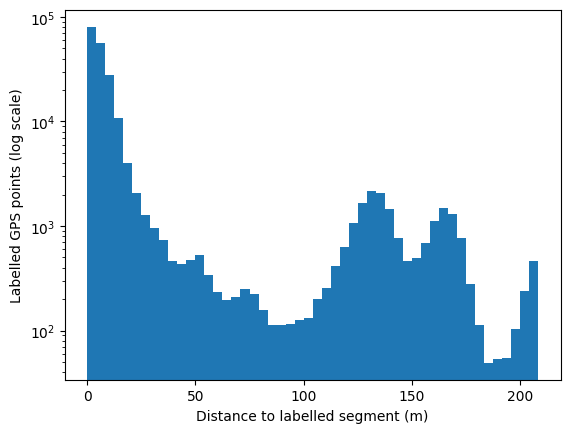

Radii: [50, 100, 140, 175, 210] | K values: [5, 10, 15, 30, 50, 100]


In [2]:
labelled_distances = []
for trip_id in trip_ids:
    labels = pd.read_csv(label_folder / f"{trip_id}.csv")
    labelled_distances.append(labels.loc[labels["true_arc_id"] >= 0, "dist_m"])
distances = pd.concat(labelled_distances, ignore_index=True)
percentiles = distances.quantile([0.95, 0.99, 0.999])
display(percentiles.rename("distance_m"))
radii = sorted({50, 100, *[int(np.ceil(d / 5) * 5) for d in percentiles]})
k_values = [5, 10, 15, 30, 50, 100]
target_miss_rate = 0.001

plt.hist(distances, bins=50, log=True)
plt.xlabel("Distance to labelled segment (m)")
plt.ylabel("Labelled GPS points (log scale)")
plt.show()
print("Radii:", radii, "| K values:", k_values)

## 2. Find and sort nearby roads

Use the same per-trip UTM projection as notebook 02. `STRtree` queries actual point-to-segment distances in metres. Each segment ID stays equal to its original arc row number.

Sort by point, distance and segment ID, with segment ID breaking distance ties. Rank 1 is the nearest segment. For any smaller radius, removing distant roads leaves these ranks unchanged. Labels are added only after this ordering is fixed.

In [3]:
def find_candidates(trip_id, radius_m):
    folder = train / trip_id
    nodes = pd.read_csv(folder / f"{trip_id}.nodes", sep=r"\s+", header=None, names=["lon", "lat"])
    arcs = pd.read_csv(folder / f"{trip_id}.arcs", sep=r"\s+", header=None, names=["start", "end"])
    labels = pd.read_csv(label_folder / f"{trip_id}.csv")
    zone = int((labels["lon"].mean() + 180) // 6) + 1
    epsg = (32600 if labels["lat"].mean() >= 0 else 32700) + zone
    projection = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
    xy = np.column_stack(projection.transform(nodes["lon"], nodes["lat"]))
    segments = shapely.linestrings(xy[arcs.to_numpy()])
    x, y = projection.transform(labels["lon"], labels["lat"])
    points = shapely.points(x, y)
    point_id, segment_id = STRtree(segments).query(points, predicate="dwithin", distance=radius_m)
    candidates = pd.DataFrame({
        "point_id": point_id,
        "segment_id": segment_id,
        "distance": shapely.distance(points[point_id], segments[segment_id]),
    }).sort_values(["point_id", "distance", "segment_id"]).reset_index(drop=True)
    candidates["rank"] = candidates.groupby("point_id").cumcount() + 1
    true_ids = labels["true_arc_id"].to_numpy()[candidates["point_id"]]
    candidates["label"] = (candidates["segment_id"] == true_ids).astype("Int8")
    candidates.loc[true_ids < 0, "label"] = pd.NA
    return labels, candidates

## 3. Sweep radius and K

A miss means a **valid labelled point** has no positive candidate. Include points with zero candidates in this denominator. Flagged points are excluded because they have no usable target.

Query the largest radius once per trip, then filter for each setting. Count candidate rows and empty shortlists across all GPS points, including flagged ones.

Swept: 00000001


Swept: 00000002


Swept: 00000003


Swept: 00000004


Swept: 00000005


Swept: 00000006


... (71 outputs left out)

Swept: 00000097


Swept: 00000098


Swept: 00000099


,radius_m,K,labelled_points,misses,candidate_rows,empty_points,miss_rate
0,50,5,206332,24817,792114,18230,0.120277
1,50,10,206332,22387,1228307,18230,0.108500
2,50,15,206332,22011,1474749,18230,0.106678
3,50,30,206332,21127,1772015,18230,0.102393
4,50,50,206332,21079,1840910,18230,0.102161
5,50,100,206332,21078,1866268,18230,0.102156
6,100,5,206332,23641,922458,1413,0.114577
7,100,10,206332,20658,1613617,1413,0.100120
8,100,15,206332,20221,2161906,1413,0.098002
9,100,30,206332,18973,3245192,1413,0.091954


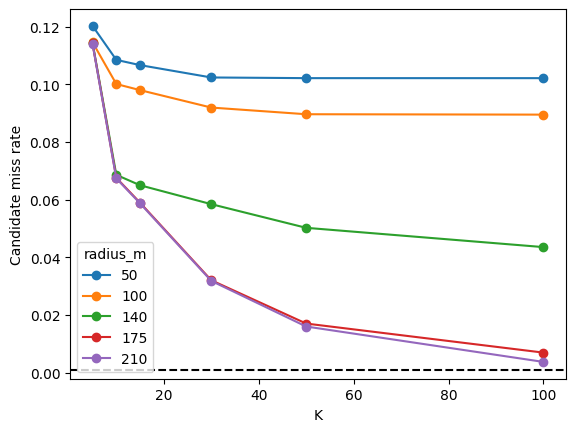

In [4]:
rows = []
for trip_id in trip_ids:
    labels, candidates = find_candidates(trip_id, max(radii))
    positives = candidates[candidates["label"].eq(1).fillna(False)]
    nearest = candidates.groupby("point_id")["distance"].min().reindex(labels.index, fill_value=np.inf)
    valid_points = (labels["true_arc_id"] >= 0).sum()
    for radius_m in radii:
        for k in k_values:
            keep = (candidates["distance"] <= radius_m) & (candidates["rank"] <= k)
            hits = ((positives["distance"] <= radius_m) & (positives["rank"] <= k)).sum()
            rows.append({"radius_m": radius_m, "K": k, "labelled_points": valid_points,
                         "misses": valid_points - hits, "candidate_rows": keep.sum(),
                         "empty_points": (nearest > radius_m).sum()})
    print("Swept:", trip_id, flush=True)

sweep = pd.DataFrame(rows).groupby(["radius_m", "K"], as_index=False).sum()
sweep["miss_rate"] = sweep["misses"] / sweep["labelled_points"]
sweep.to_csv(output / "sweep.csv", index=False)
display(sweep)
sweep.pivot(index="K", columns="radius_m", values="miss_rate").plot(marker="o")
plt.ylabel("Candidate miss rate")
plt.axhline(target_miss_rate, color="black", linestyle="--")
plt.show()

## 4. Select settings

Choose the fewest candidate rows among settings meeting the 0.1% miss-rate target. If none meet it, keep the setting with the lowest measured miss rate, breaking ties by row count, and explicitly report the unmet target.

This is a training-data choice, not a guarantee of recall on new trips. Freeze these settings for later evaluation.

In [5]:
eligible = sweep[sweep["miss_rate"] <= target_miss_rate]
if eligible.empty:
    print("Target not reached. Selecting the lowest measured miss rate.")
    eligible = sweep[sweep["miss_rate"] == sweep["miss_rate"].min()]
chosen = eligible.sort_values(["candidate_rows", "radius_m", "K"]).iloc[0]
radius_m, k = int(chosen["radius_m"]), int(chosen["K"])
settings = {"radius_m": radius_m, "K": k, "target_miss_rate": target_miss_rate,
            "train_miss_rate": float(chosen["miss_rate"]), "labelled_points": int(chosen["labelled_points"])}
(output / "settings.json").write_text(json.dumps(settings, indent=2) + "\n")
print(settings)

Target not reached. Selecting the lowest measured miss rate.
{'radius_m': 210, 'K': 100, 'target_miss_rate': 0.001, 'train_miss_rate': 0.0037027702925382395, 'labelled_points': 206332}


## 5. Save candidates and ranker groups

`candidates.csv` has `trip_id, group_id, point_id, segment_id, distance, label`. Point IDs are row numbers within a trip; group IDs are unique across all trips. Rows are consecutive and sorted by group ID. Missing labels mean flagged GPS, not negative examples.

`ranker_candidates.csv` keeps only groups with at least two candidates and exactly one positive. Groups with no positive cannot teach this ranker a preference and are excluded. `ranker_groups.csv` records the matching group sizes in row order; pass its `group_size` values as XGBoost's `group` argument. Split by **trip**, and recompute group sizes after splitting.

`points.csv` retains every point, including empty and single-candidate shortlists, so prediction and the HMM can account for them. A single candidate has softmax probability 1; an empty shortlist needs separate handling later. Ground-truth fields and labels are training metadata, not prediction features.

In [6]:
offset = 0
checks = []
for trip_id in trip_ids:
    labels, candidates = find_candidates(trip_id, radius_m)
    candidates = candidates[candidates["rank"] <= k].copy()
    candidates["group_id"] = candidates["point_id"] + offset
    candidates["trip_id"] = trip_id
    candidates = candidates[["trip_id", "group_id", "point_id", "segment_id", "distance", "label"]]
    assert candidates["group_id"].is_monotonic_increasing

    sizes = candidates.groupby("group_id")["label"].agg(["size", "sum"])
    train_ids = sizes.index[(sizes["size"] > 1) & (sizes["sum"] == 1)]
    ranker = candidates[candidates["group_id"].isin(train_ids)]
    groups = ranker.groupby("group_id", sort=False).agg(
        trip_id=("trip_id", "first"), point_id=("point_id", "first"), group_size=("segment_id", "size")
    ).reset_index()
    assert groups["group_size"].sum() == len(ranker)
    assert (groups["group_size"] >= 2).all()
    assert (ranker.groupby("group_id")["label"].sum() == 1).all()

    points = labels[["true_arc_id", "bad_gps"]].copy()
    points.insert(0, "point_id", np.arange(len(labels)))
    points.insert(0, "group_id", points["point_id"] + offset)
    points.insert(0, "trip_id", trip_id)
    counts = candidates.groupby("point_id").size()
    hits = candidates.groupby("point_id")["label"].sum()
    points["candidate_count"] = counts.reindex(labels.index, fill_value=0)
    points["true_in_candidates"] = hits.reindex(labels.index, fill_value=0).eq(1).astype("boolean")
    points.loc[points["bad_gps"], "true_in_candidates"] = pd.NA
    valid = ~points["bad_gps"]
    misses = (valid & points["true_in_candidates"].eq(False)).sum()
    checks.append({"trip_id": trip_id, "gps_points": len(points), "labelled_points": valid.sum(),
                   "misses": misses, "empty_points": (points["candidate_count"] == 0).sum(),
                   "single_candidate_points": (points["candidate_count"] == 1).sum(),
                   "candidate_rows": len(candidates), "ranker_rows": len(ranker), "ranker_groups": len(groups)})
    for frame, filename in [(candidates, "candidates.csv"), (ranker, "ranker_candidates.csv"),
                            (groups, "ranker_groups.csv"), (points, "points.csv")]:
        frame.to_csv(output / filename, mode="w" if offset == 0 else "a", header=offset == 0, index=False)
    offset += len(labels)
    print("Saved:", trip_id, flush=True)

summary = pd.DataFrame(checks)
summary["miss_rate"] = summary["misses"] / summary["labelled_points"]
summary.to_csv(output / "summary.csv", index=False)
assert summary["candidate_rows"].sum() == int(chosen["candidate_rows"])
assert summary["misses"].sum() == int(chosen["misses"])
print("Total candidate rows:", summary["candidate_rows"].sum())
print("Ranker rows:", summary["ranker_rows"].sum(), "| Ranker groups:", summary["ranker_groups"].sum())
display(summary.sort_values("miss_rate", ascending=False).head(10))

Saved: 00000001


Saved: 00000002


Saved: 00000003


Saved: 00000004


Saved: 00000005


Saved: 00000006


... (72 outputs left out)

Saved: 00000098


Saved: 00000099


Total candidate rows: 11678902
Ranker rows: 11425937 | Ranker groups: 205549


,trip_id,gps_points,labelled_points,misses,empty_points,single_candidate_points,candidate_rows,ranker_rows,ranker_groups,miss_rate
44,00000054,19313,17853,693,0,0,1875417,1661173,17160,0.038817
1,00000002,7243,6830,70,74,0,452648,417330,6760,0.010249
35,00000043,2322,2304,1,0,0,144272,143435,2303,0.000434
50,00000062,3378,3378,0,0,0,244822,244822,3378,0.000000
57,00000071,850,850,0,0,0,62182,62182,850,0.000000
56,00000070,2076,2076,0,0,0,97456,97456,2076,0.000000
55,00000069,2067,2067,0,0,0,180986,180986,2067,0.000000
54,00000068,747,747,0,0,0,49902,49902,747,0.000000
53,00000066,4325,4142,0,0,0,56114,54088,4142,0.000000
52,00000064,2093,2093,0,0,0,89228,89228,2093,0.000000
